# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot regional T2m in 1950, 2000, 2050 to see where maximum baroclinicity is changing

**Notebook by Alice DuVivier - June 2026**

In [1]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import cmocean
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick

## Load data
- regional, monthly data by decade

### Get T2m data
- monthly data by decade

In [2]:
# set path where the som finalist files are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/data_for_composites/'

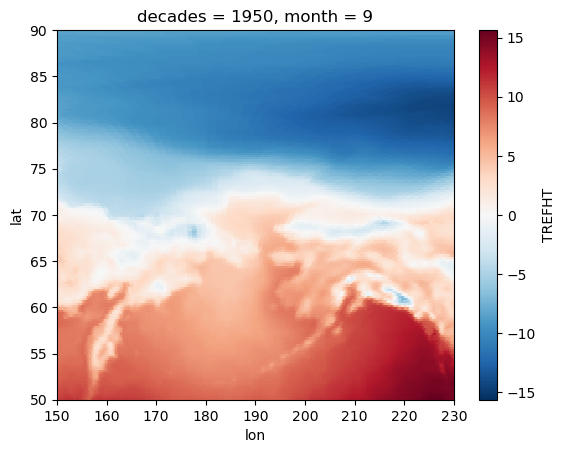

In [3]:
# Load SST data for larger area than only training area - set file name
var_in = 'TREFHT'
fin = var_in+'_monthly_autumn_decadal_alaska_cam_grid.nc'

# load data
ds = xr.open_dataset(dir_in+fin)

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

# keep only the variable of interest
ds_t2m = ds[var_in]

# convert to C from K
ds_t2m = ds_t2m - 273.15

ds_t2m.isel(ensemble=0,decades=0,month=0).plot()

In [4]:
# set latitude and longitude
lat = ds.lat
lon = ds.lon

## Get monthly ensemble mean data for just three decades
- Get decades: 1950, 2000, 2050
- Subset for months then get ensemble means over ensemble and all three years in a decade

In [5]:
# T2m
t2m_1950 = ds_t2m.sel(decades = 1950)
t2m_2000 = ds_t2m.sel(decades = 2000)
t2m_2050 = ds_t2m.sel(decades = 2050)

In [6]:
# averages
# 1950
t2m_1950_sep_avg = t2m_1950.where(t2m_1950.month == 9, drop=True).mean(dim=['ensemble', 'month'])
t2m_1950_oct_avg = t2m_1950.where(t2m_1950.month == 10, drop=True).mean(dim=['ensemble', 'month'])
t2m_1950_nov_avg = t2m_1950.where(t2m_1950.month == 11, drop=True).mean(dim=['ensemble', 'month'])
t2m_1950_dec_avg = t2m_1950.where(t2m_1950.month == 12, drop=True).mean(dim=['ensemble', 'month'])

# 2000
t2m_2000_sep_avg = t2m_2000.where(t2m_2000.month == 9, drop=True).mean(dim=['ensemble', 'month'])
t2m_2000_oct_avg = t2m_2000.where(t2m_2000.month == 10, drop=True).mean(dim=['ensemble', 'month'])
t2m_2000_nov_avg = t2m_2000.where(t2m_2000.month == 11, drop=True).mean(dim=['ensemble', 'month'])
t2m_2000_dec_avg = t2m_2000.where(t2m_2000.month == 12, drop=True).mean(dim=['ensemble', 'month'])

# 2050
t2m_2050_sep_avg = t2m_2050.where(t2m_2050.month == 9, drop=True).mean(dim=['ensemble', 'month'])
t2m_2050_oct_avg = t2m_2050.where(t2m_2050.month == 10, drop=True).mean(dim=['ensemble', 'month'])
t2m_2050_nov_avg = t2m_2050.where(t2m_2050.month == 11, drop=True).mean(dim=['ensemble', 'month'])
t2m_2050_dec_avg = t2m_2050.where(t2m_2050.month == 12, drop=True).mean(dim=['ensemble', 'month'])

In [7]:
# standard deviation
# 1950
t2m_1950_sep_std = t2m_1950.where(t2m_1950.month == 9, drop=True).std(dim=['ensemble', 'month'])
t2m_1950_oct_std = t2m_1950.where(t2m_1950.month == 10, drop=True).std(dim=['ensemble', 'month'])
t2m_1950_nov_std = t2m_1950.where(t2m_1950.month == 11, drop=True).std(dim=['ensemble', 'month'])
t2m_1950_dec_std = t2m_1950.where(t2m_1950.month == 12, drop=True).std(dim=['ensemble', 'month'])

# 2000
t2m_2000_sep_std = t2m_2000.where(t2m_2000.month == 9, drop=True).std(dim=['ensemble', 'month'])
t2m_2000_oct_std = t2m_2000.where(t2m_2000.month == 10, drop=True).std(dim=['ensemble', 'month'])
t2m_2000_nov_std = t2m_2000.where(t2m_2000.month == 11, drop=True).std(dim=['ensemble', 'month'])
t2m_2000_dec_std = t2m_2000.where(t2m_2000.month == 12, drop=True).std(dim=['ensemble', 'month'])

# 2050
t2m_2050_sep_std = t2m_2050.where(t2m_2050.month == 9, drop=True).std(dim=['ensemble', 'month'])
t2m_2050_oct_std = t2m_2050.where(t2m_2050.month == 10, drop=True).std(dim=['ensemble', 'month'])
t2m_2050_nov_std = t2m_2050.where(t2m_2050.month == 11, drop=True).std(dim=['ensemble', 'month'])
t2m_2050_dec_std = t2m_2050.where(t2m_2050.month == 12, drop=True).std(dim=['ensemble', 'month'])

## Plot Maps by decade and month to compare

In [9]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v3/'

In [10]:
# set lat/lon bounds
lat_max = 79
lat_min = 53
lon_max = 205
lon_min = 175
lon_avg = 191.625

In [11]:
# lats and lons for a transect line
lons = [lon_avg, lon_avg]
lats = [50, 90]

### Create T2m mean plots

In [12]:
## set colors and levels for sst
cmap_in = cmocean.cm.thermal
vmin_in = -20
vmax_in = 20
levels_in = np.arange(-20,25,5)
ticks_in = [-20, -15, -10, -5, 0, 5, 10, 15, 20]
units_in = 'C'
var_in = 'T2m'

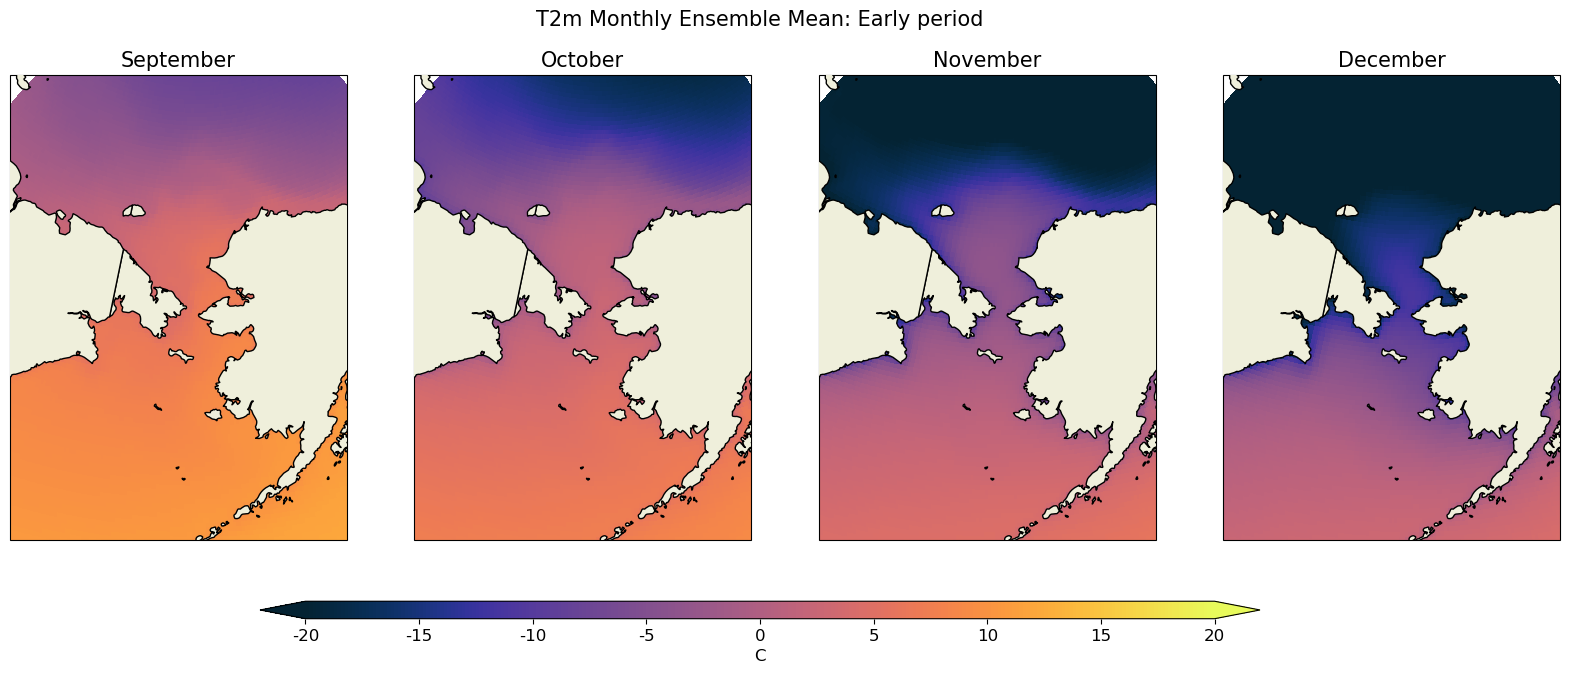

In [16]:
### Choose year and data to plot
yyyy = '1950'

# set data to plot
sep_data = t2m_1950_sep_avg
oct_data = t2m_1950_oct_avg
nov_data = t2m_1950_nov_avg
dec_data = t2m_1950_dec_avg

#### 
# create figure
fig = plt.figure(figsize=(20,7))
fout = 'supp_decadal_'+var_in+'_regional_avg_'+yyyy

# Make subplots - note it's nrow x ncol x index (starting upper left)
### Sept
ax = fig.add_subplot(1,4,1, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon, lat, sep_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('September',fontsize=15)

### Oct
ax = fig.add_subplot(1,4,2, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon, lat, oct_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('October',fontsize=15)

### Nov
ax = fig.add_subplot(1,4,3, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon, lat, nov_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('November',fontsize=15)

### Dec
ax = fig.add_subplot(1,4,4, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = pcm = ax.pcolormesh(lon, lat, dec_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('December',fontsize=15)

# Finalize figure and save
#add title
fig.suptitle(var_in+' Monthly Ensemble Mean: Early period',fontsize=15, y=0.92)

# colorbar stuff
cbar_ax = fig.add_axes([0.25,0.05,0.5,0.025]) 
cbar = fig.colorbar(cs, cax=cbar_ax, ticks=ticks_in[:],orientation='horizontal', extend='both')
cbar.ax.set_xticklabels(list(ticks_in))
cbar.ax.tick_params(labelsize=12)
cbar.set_label(units_in, fontsize=12)

# save figure
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)

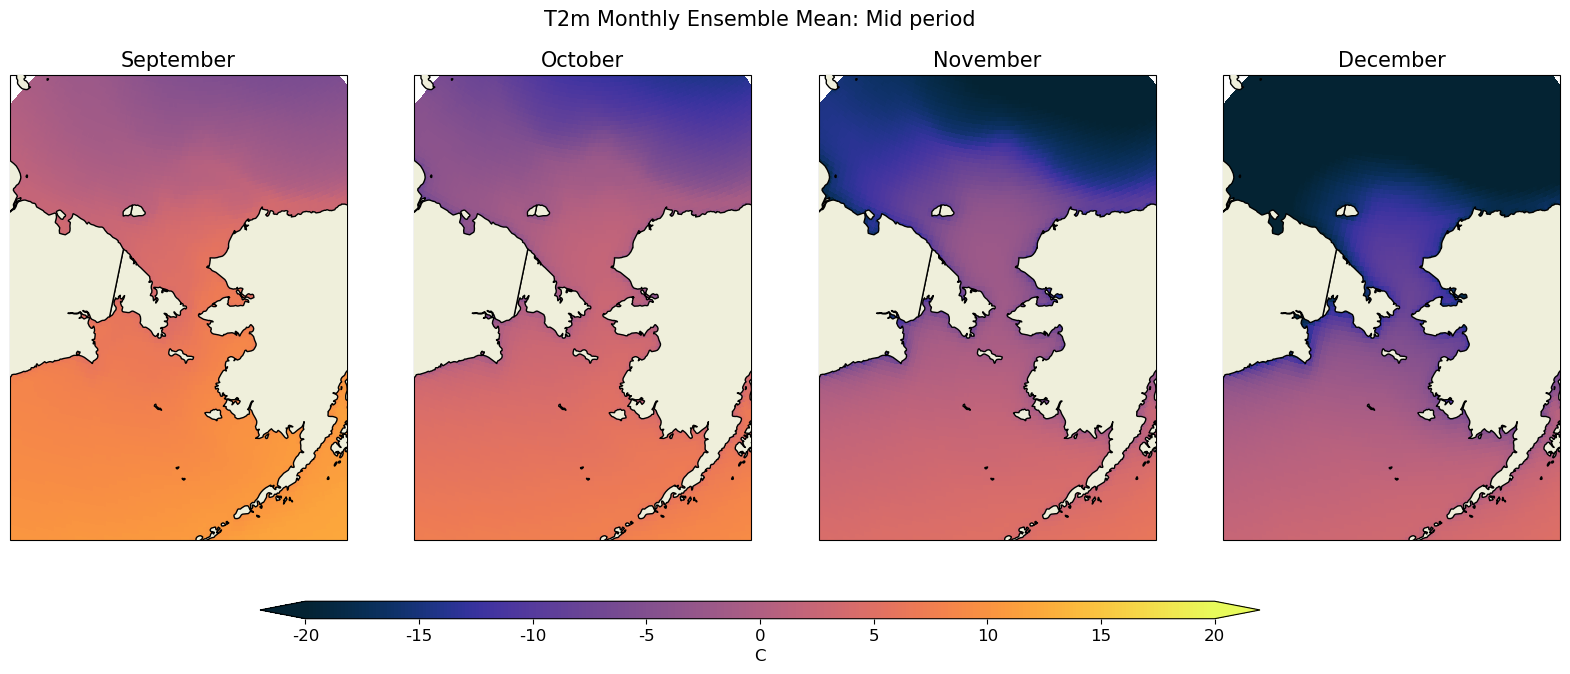

In [17]:
### Choose year and data to plot
yyyy = '2000'

# set data to plot
sep_data = t2m_2000_sep_avg
oct_data = t2m_2000_oct_avg
nov_data = t2m_2000_nov_avg
dec_data = t2m_2000_dec_avg

#### 
# create figure
fig = plt.figure(figsize=(20,7))
fout = 'supp_decadal_'+var_in+'_regional_avg_'+yyyy

# Make subplots - note it's nrow x ncol x index (starting upper left)
### Sept
ax = fig.add_subplot(1,4,1, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon, lat, sep_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('September',fontsize=15)

### Oct
ax = fig.add_subplot(1,4,2, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon, lat, oct_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('October',fontsize=15)

### Nov
ax = fig.add_subplot(1,4,3, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon, lat, nov_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('November',fontsize=15)

### Dec
ax = fig.add_subplot(1,4,4, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = pcm = ax.pcolormesh(lon, lat, dec_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('December',fontsize=15)

# Finalize figure and save
#add title
fig.suptitle(var_in+' Monthly Ensemble Mean: Mid period',fontsize=15, y=0.92)

# colorbar stuff
cbar_ax = fig.add_axes([0.25,0.05,0.5,0.025]) 
cbar = fig.colorbar(cs, cax=cbar_ax, ticks=ticks_in[:],orientation='horizontal', extend='both')
cbar.ax.set_xticklabels(list(ticks_in))
cbar.ax.tick_params(labelsize=12)
cbar.set_label(units_in, fontsize=12)

# save figure
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)

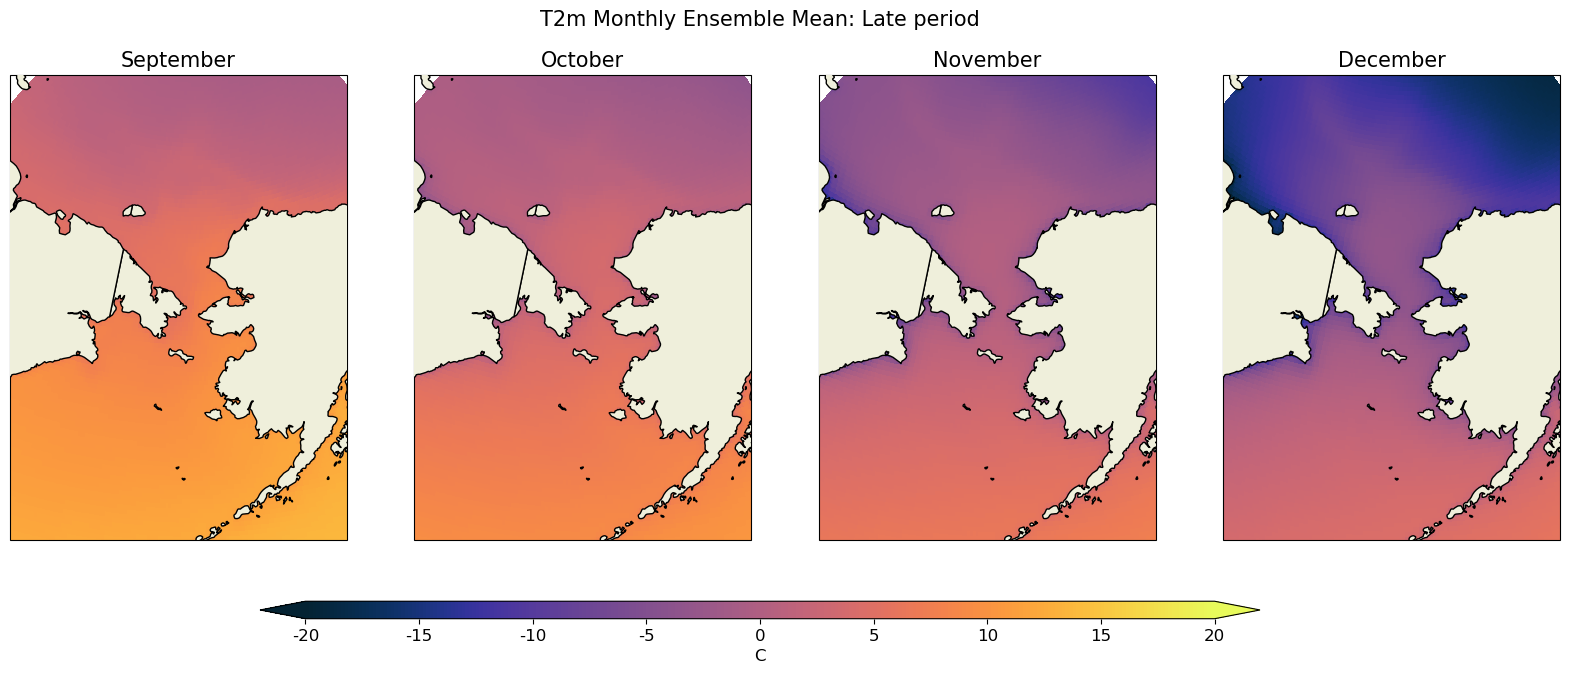

In [18]:
### Choose year and data to plot
yyyy = '2050'

# set data to plot
sep_data = t2m_2050_sep_avg
oct_data = t2m_2050_oct_avg
nov_data = t2m_2050_nov_avg
dec_data = t2m_2050_dec_avg

#### 
# create figure
fig = plt.figure(figsize=(20,7))
fout = 'supp_decadal_'+var_in+'_regional_avg_'+yyyy

# Make subplots - note it's nrow x ncol x index (starting upper left)
### Sept
ax = fig.add_subplot(1,4,1, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon, lat, sep_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('September',fontsize=15)

### Oct
ax = fig.add_subplot(1,4,2, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon, lat, oct_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('October',fontsize=15)

### Nov
ax = fig.add_subplot(1,4,3, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = ax.pcolormesh(lon, lat, nov_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('November',fontsize=15)

### Dec
ax = fig.add_subplot(1,4,4, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
# add SST
cs = pcm = ax.pcolormesh(lon, lat, dec_data, vmin=vmin_in, vmax=vmax_in, cmap=cmap_in, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND,zorder=50,edgecolor='k')
plt.title('December',fontsize=15)

# Finalize figure and save
#add title
fig.suptitle(var_in+' Monthly Ensemble Mean: Late period',fontsize=15, y=0.92)

# colorbar stuff
cbar_ax = fig.add_axes([0.25,0.05,0.5,0.025]) 
cbar = fig.colorbar(cs, cax=cbar_ax, ticks=ticks_in[:],orientation='horizontal', extend='both')
cbar.ax.set_xticklabels(list(ticks_in))
cbar.ax.tick_params(labelsize=12)
cbar.set_label(units_in, fontsize=12)

# save figure
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)